In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

tf.keras.utils.set_random_seed(42)

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Churn_Modelling.csv to Churn_Modelling.csv


In [3]:
import io

filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:

df = df.drop(
    columns=["RowNumber", "CustomerId", "Surname"],
    errors="ignore"
)


X = df.drop(columns=["Exited"])
y = df["Exited"].astype(int)

X = pd.get_dummies(
    X,
    columns=["Geography", "Gender"],
    drop_first=True,
    dtype=int
)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (10000, 11)
Target shape: (10000,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 8000
Testing samples: 2000


In [6]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype("float32")
X_test = scaler.transform(X_test).astype("float32")

y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

print("Normalization completed.")

Normalization completed.


In [7]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 929 (3.63 KB)

 Trainable params: 929 (3.63 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

print("Training completed.")

Epoch 1/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.7097 - loss: 0.6039 - val_accuracy: 0.8100 - val_loss: 0.4878
Epoch 2/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7954 - loss: 0.4931 - val_accuracy: 0.8112 - val_loss: 0.4397
Epoch 3/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8029 - loss: 0.4564 - val_accuracy: 0.8150 - val_loss: 0.4185
Epoch 4/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8075 - loss: 0.4436 - val_accuracy: 0.8313 - val_loss: 0.4079
Epoch 5/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8136 - loss: 0.4323 - val_accuracy: 0.8363 - val_loss: 0.3993
Epoch 6/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8175 - loss: 0.4226 - val_accuracy: 0.8413 - val_loss: 0.3907
Epoch 7/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8238 - loss: 0.4169 - val_accuracy: 0.8450 - val_loss: 0.3816
Epoch 8/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8286 - loss: 0.4113 - val_accuracy: 0.8462 - val_loss

In [9]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

probabilities = model.predict(X_test, verbose=0)
y_pred = (probabilities >= 0.5).astype(int).ravel()

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:\n", cm)

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Stay", "Churn"],
    zero_division=0
))

Test Accuracy: 0.855

Confusion Matrix:
 [[1552   41]
 [ 249  158]]

Classification Report:
              precision    recall  f1-score   support

        Stay       0.86      0.97      0.91      1593
       Churn       0.79      0.39      0.52       407

    accuracy                           0.85      2000
   macro avg       0.83      0.68      0.72      2000
weighted avg       0.85      0.85      0.83      2000



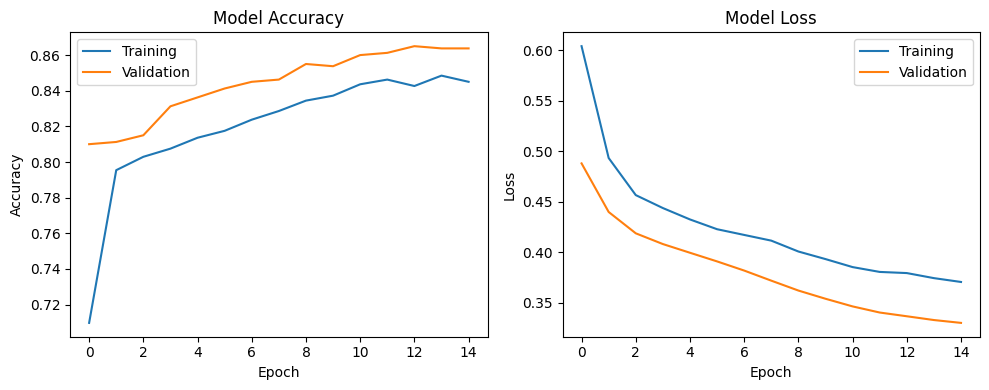

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=200)
plt.show()

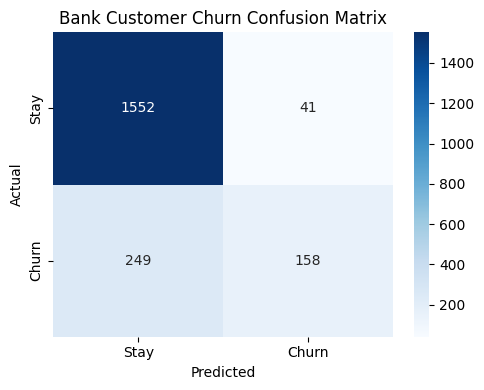

In [11]:
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stay", "Churn"],
    yticklabels=["Stay", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Bank Customer Churn Confusion Matrix")
plt.tight_layout()

plt.savefig("confusion_matrix.png", dpi=200)
plt.show()